# Verify Local Image Datasets

This notebook verifies the image datasets stored under the clean repository's `data/` directory. It loads every public dataset without network access, checks the expected split sizes, and displays example images.

**Audience:** researchers preparing local image experiments.

**Prerequisites:** run this notebook in the `memcompgen` Conda environment after downloading the datasets.

**Result:** MNIST, CIFAR-10, and Oxford Flowers102 must pass. FFHQ is reported separately because it requires the official NVIDIA download and a non-commercial dataset license.


## Outline

1. Resolve the repository and data paths.
2. Load each public dataset with downloading disabled.
3. check split sizes and display examples.
4. Check whether FFHQ thumbnails are present at the legacy path.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from torchvision import datasets


def find_repo_root(start):
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "mem_param_src").is_dir():
            return candidate
    raise RuntimeError("Could not locate the mem_param_clean repository root.")


REPO_ROOT = find_repo_root(Path.cwd().resolve())
DATA_ROOT = REPO_ROOT / "data"
FFHQ_ROOT = DATA_ROOT / "ffhq" / "thumbnails128x128"
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print(f"repository: {REPO_ROOT}")
print(f"data root:  {DATA_ROOT}")


Matplotlib is building the font cache; this may take a moment.


repository: /Users/mohammadaljaff/Desktop/PhD/projects/mem_param/mem_param_clean
data root:  /Users/mohammadaljaff/Desktop/PhD/projects/mem_param/mem_param_clean/data


## Load the public datasets

`download=False` is deliberate: this cell proves the files already exist locally and does not hide a missing dataset by downloading it during verification.


In [2]:
loaded = {
    "MNIST train": datasets.MNIST(DATA_ROOT, train=True, download=False),
    "MNIST test": datasets.MNIST(DATA_ROOT, train=False, download=False),
    "CIFAR-10 train": datasets.CIFAR10(DATA_ROOT, train=True, download=False),
    "CIFAR-10 test": datasets.CIFAR10(DATA_ROOT, train=False, download=False),
    "Flowers102 train": datasets.Flowers102(DATA_ROOT, split="train", download=False),
    "Flowers102 val": datasets.Flowers102(DATA_ROOT, split="val", download=False),
    "Flowers102 test": datasets.Flowers102(DATA_ROOT, split="test", download=False),
}

expected_sizes = {
    "MNIST train": 60_000,
    "MNIST test": 10_000,
    "CIFAR-10 train": 50_000,
    "CIFAR-10 test": 10_000,
    "Flowers102 train": 1_020,
    "Flowers102 val": 1_020,
    "Flowers102 test": 6_149,
}

for name, dataset in loaded.items():
    actual = len(dataset)
    expected = expected_sizes[name]
    assert actual == expected, f"{name}: expected {expected:,}, found {actual:,}"
    print(f"PASS  {name:<20} {actual:>6,} examples")


PASS  MNIST train          60,000 examples
PASS  MNIST test           10,000 examples
PASS  CIFAR-10 train       50,000 examples
PASS  CIFAR-10 test        10,000 examples
PASS  Flowers102 train      1,020 examples
PASS  Flowers102 val        1,020 examples
PASS  Flowers102 test       6,149 examples


## Display examples

The gallery reads images from each training split. Successful rendering checks more than archive presence: it checks that Torchvision can decode the extracted files.


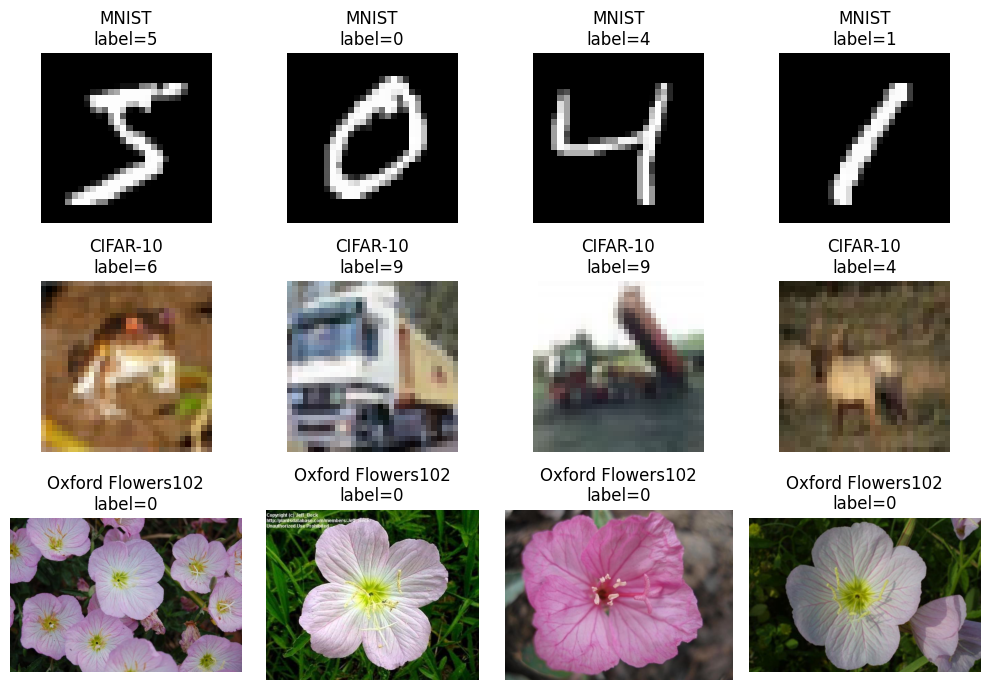

In [3]:
gallery_datasets = [
    ("MNIST", loaded["MNIST train"]),
    ("CIFAR-10", loaded["CIFAR-10 train"]),
    ("Oxford Flowers102", loaded["Flowers102 train"]),
]

fig, axes = plt.subplots(len(gallery_datasets), 4, figsize=(10, 7))
for row, (dataset_name, dataset) in enumerate(gallery_datasets):
    for column in range(4):
        image, label = dataset[column]
        axes[row, column].imshow(image, cmap="gray" if dataset_name == "MNIST" else None)
        axes[row, column].set_title(f"{dataset_name}\nlabel={label}")
        axes[row, column].axis("off")
plt.tight_layout()
plt.show()


## FFHQ status

The clean setup preserves the old repository's expected location: `data/ffhq/thumbnails128x128/`. The official thumbnail release contains 70,000 128×128 PNG files and is approximately 1.95 GB. Absence is reported without failing the checks above.


In [4]:
ffhq_files = []
if FFHQ_ROOT.is_dir():
    ffhq_files = sorted(
        path for path in FFHQ_ROOT.rglob("*")
        if path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES
    )

if ffhq_files:
    print(f"FFHQ present: {len(ffhq_files):,} images under {FFHQ_ROOT}")
    if len(ffhq_files) != 70_000:
        print("WARNING: the official thumbnail release contains 70,000 images.")

    fig, axes = plt.subplots(1, 4, figsize=(8, 2))
    for axis, image_path in zip(axes, ffhq_files[:4]):
        image = plt.imread(image_path)
        axis.imshow(image)
        axis.set_title(image_path.name)
        axis.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print(f"FFHQ not downloaded: {FFHQ_ROOT}")


FFHQ not downloaded: /Users/mohammadaljaff/Desktop/PhD/projects/mem_param/mem_param_clean/data/ffhq/thumbnails128x128


## Optional exercise

Change `SAMPLE_INDEX` and confirm that one example from each public dataset still decodes. This is useful after moving or copying the `data/` directory.


In [5]:
SAMPLE_INDEX = 10
for name in ("MNIST train", "CIFAR-10 train", "Flowers102 train"):
    image, label = loaded[name][SAMPLE_INDEX]
    print(f"{name:<20} image_size={image.size!s:<12} label={label}")


MNIST train          image_size=(28, 28)     label=3
CIFAR-10 train       image_size=(32, 32)     label=4
Flowers102 train     image_size=(500, 682)   label=1


## Interpretation and pitfalls

- All `PASS` lines plus a rendered gallery confirm that the three public datasets are locally usable.
- Do not set `download=True` in multi-process training jobs. Download once before submission.
- The entire `data/` directory is intentionally ignored by Git. Copy or stage it separately when moving to Berzelius.
- FFHQ is licensed for non-commercial use under CC BY-NC-SA 4.0; retain the required attribution if it is added.
